# SpaceX Falcon 9 Landing Classification

**Purpose:** Use the original SpaceX launch dataset to explore landing outcomes and compare four introductory classification models.

## Important interpretation
For this exercise, `Successful_Landing = 1` means the landing outcome is explicitly recorded as `Success`, `Success (drone ship)`, or `Success (ground pad)`. All other recorded outcomes are labelled `0` (not recorded as a confirmed successful landing). **A zero does not always mean a crash**: it also includes outcomes such as `No attempt`, `Controlled (ocean)`, and `Precluded (drone ship)`.

This dataset contains only 101 launches, so model results are exploratory and should not be treated as reliable operational predictions.


## 1. Import libraries and load the data

Put `Spacex.csv` in the same folder as this notebook. The filename is case-sensitive on some systems.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv('/content/Spacex.csv')
print("Rows and columns:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())


Rows and columns: (101, 10)


,Date,Time (UTC),Booster_Version,Launch_Site,Payload,PAYLOAD_MASS__KG_,Orbit,Customer,Mission_Outcome,Landing_Outcome
0,2010-06-04,18:45:00,F9 v1.0 B0003,CCAFS LC-40,Dragon Spacecraft Qualification Unit,0,LEO,SpaceX,Success,Failure (parachute)
1,2010-12-08,15:43:00,F9 v1.0 B0004,CCAFS LC-40,"Dragon demo flight C1, two CubeSats, barrel of...",0,LEO (ISS),NASA (COTS) NRO,Success,Failure (parachute)
2,2012-05-22,7:44:00,F9 v1.0 B0005,CCAFS LC-40,Dragon demo flight C2,525,LEO (ISS),NASA (COTS),Success,No attempt
3,2012-10-08,0:35:00,F9 v1.0 B0006,CCAFS LC-40,SpaceX CRS-1,500,LEO (ISS),NASA (CRS),Success,No attempt
4,2013-03-01,15:10:00,F9 v1.0 B0007,CCAFS LC-40,SpaceX CRS-2,677,LEO (ISS),NASA (CRS),Success,No attempt



Column names:
['Date', 'Time (UTC)', 'Booster_Version', 'Launch_Site', 'Payload', 'PAYLOAD_MASS__KG_', 'Orbit', 'Customer', 'Mission_Outcome', 'Landing_Outcome']


## 2. Check and prepare the landing target

In [12]:
# Check the original landing outcome categories and counts
display(df["Landing_Outcome"].value_counts(dropna=False).to_frame("Number of launches"))

# Define only explicitly confirmed landing successes as class 1.
successful_outcomes = [
    "Success",
    "Success (drone ship)",
    "Success (ground pad)"
]

df["Successful_Landing"] = (
    df["Landing_Outcome"].astype(str).str.strip().isin(successful_outcomes)
).astype(int)

print("Target counts:")
display(df["Successful_Landing"].value_counts().rename(index={0: "Not confirmed successful", 1: "Confirmed successful"}).to_frame("Count"))

print("Confirmed successful landings:", int(df["Successful_Landing"].sum()))
print("Other recorded outcomes:", int((df["Successful_Landing"] == 0).sum()))


,Number of launches
Landing_Outcome,
Success,38
No attempt,21
Success (drone ship),14
Success (ground pad),9
Controlled (ocean),5
Failure (drone ship),5
Failure,3
Uncontrolled (ocean),2
Failure (parachute),2


Target counts:


,Count
Successful_Landing,
Confirmed successful,61
Not confirmed successful,40


Confirmed successful landings: 61
Other recorded outcomes: 40


## 3. Explore the data

The first chart shows how many records fall into each landing-outcome category. The second shows the number of confirmed successful landings versus all other outcomes.

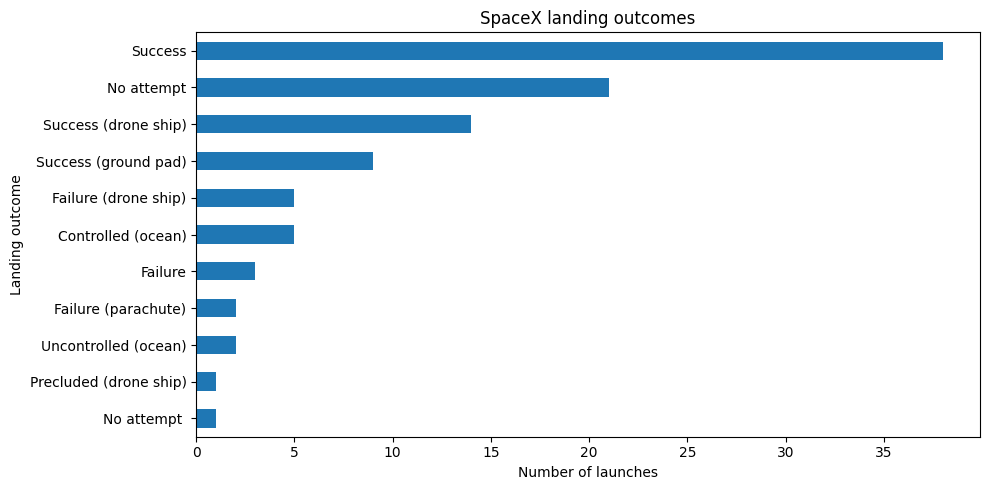

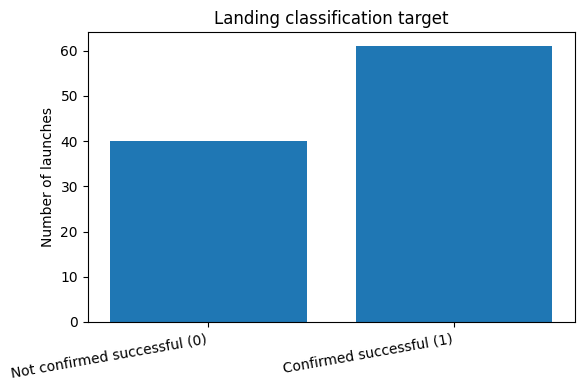

In [ ]:
outcome_counts = df["Landing_Outcome"].fillna("Missing").value_counts()
plt.figure(figsize=(10, 5))
outcome_counts.sort_values().plot(kind="barh")
plt.title("SpaceX landing outcomes")
plt.xlabel("Number of launches")
plt.ylabel("Landing outcome")
plt.tight_layout()
plt.show()

target_counts = df["Successful_Landing"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(["Not confirmed successful (0)", "Confirmed successful (1)"],
        [target_counts.get(0, 0), target_counts.get(1, 0)])
plt.title("Landing classification target")
plt.ylabel("Number of launches")
plt.xticks(rotation=10, ha="right")
plt.tight_layout()
plt.show()


## 4. Select predictors

We will use information available about each launch: launch site, booster version, payload mass, and orbit.

We deliberately exclude `Landing_Outcome` because it is used to create the answer/target. We also exclude `Mission_Outcome` because it describes mission success, not landing success. The payload name and customer are omitted to keep this small beginner model manageable.

In [13]:
feature_columns = [
    "Launch_Site",
    "Booster_Version",
    "PAYLOAD_MASS__KG_",
    "Orbit"
]

required_columns = feature_columns + ["Landing_Outcome", "Successful_Landing"]
missing = [column for column in required_columns if column not in df.columns]
if missing:
    raise ValueError(f"These required columns are missing: {missing}")

model_data = df[feature_columns + ["Successful_Landing"]].copy()
X = model_data[feature_columns]
y = model_data["Successful_Landing"]

print("Predictor columns:", feature_columns)
print("Number of records:", len(model_data))
print("Target balance:")
display(y.value_counts().rename(index={0: "Class 0", 1: "Class 1"}).to_frame("Count"))


Predictor columns: ['Launch_Site', 'Booster_Version', 'PAYLOAD_MASS__KG_', 'Orbit']
Number of records: 101
Target balance:


,Count
Successful_Landing,
Class 1,61
Class 0,40


## 5. Split the data and prepare categorical/numeric columns

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

categorical_features = ["Launch_Site", "Booster_Version", "Orbit"]
numeric_features = ["PAYLOAD_MASS__KG_"]

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 80
Testing records: 21


## 6. Train and compare four classification models

We use stratified 5-fold cross-validation on the training data. This gives a more useful comparison than relying on one small test split alone. The folds preserve the approximate class balance.

In [19]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Support Vector Machine": SVC(class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced", max_depth=4),
    "K-Nearest Neighbours": KNeighborsClassifier(n_neighbors=5)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
comparison_rows = []
pipelines = {}

for name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipelines[name] = pipeline

    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv,
        scoring={"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"},
        error_score="raise"
    )
    comparison_rows.append({
        "Model": name,
        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "CV Accuracy Std": scores["test_accuracy"].std(),
        "Mean CV Balanced Accuracy": scores["test_balanced_accuracy"].mean()
    })

comparison = pd.DataFrame(comparison_rows).sort_values(
    "Mean CV Accuracy", ascending=False
).reset_index(drop=True)

display(comparison.round(3))


,Model,Mean CV Accuracy,CV Accuracy Std,Mean CV Balanced Accuracy
0,Logistic Regression,0.625,0.105,0.602
1,Support Vector Machine,0.612,0.115,0.584
2,K-Nearest Neighbours,0.600,0.064,0.575
3,Decision Tree,0.550,0.073,0.553


## 7. Chart the model comparison

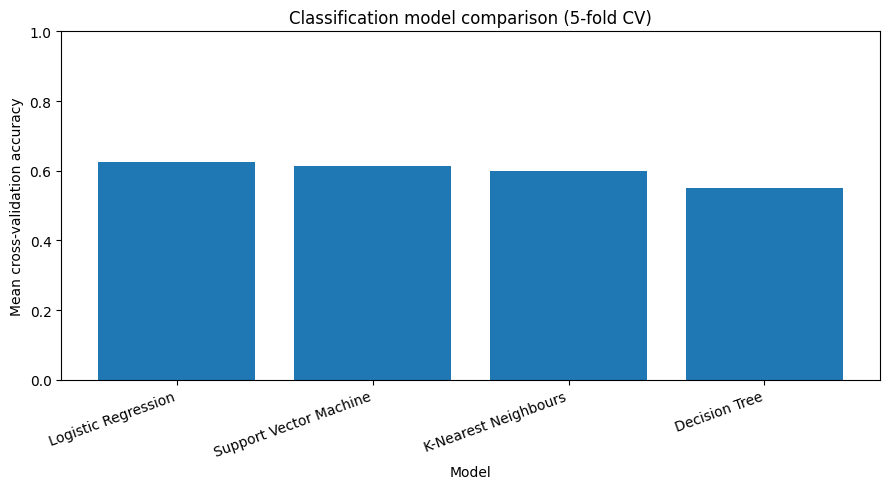

Saved: SpaceX_Model_Accuracy_Comparison.png


In [20]:
plt.figure(figsize=(9, 5))
plt.bar(comparison["Model"], comparison["Mean CV Accuracy"])
plt.ylim(0, 1)
plt.title("Classification model comparison (5-fold CV)")
plt.ylabel("Mean cross-validation accuracy")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("SpaceX_Model_Accuracy_Comparison.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: SpaceX_Model_Accuracy_Comparison.png")


## 8. Fit the best model and evaluate it on the held-out test data

The model with the highest mean cross-validation accuracy is selected. We then evaluate it once on the test set. Accuracy alone can be misleading when classes are uneven, so we also report balanced accuracy, the confusion matrix, and precision/recall.

Selected model: Logistic Regression
Test accuracy: 0.714
Test balanced accuracy: 0.697

Classification report:
                          precision    recall  f1-score   support

Not confirmed successful       0.62      0.62      0.62         8
    Confirmed successful       0.77      0.77      0.77        13

                accuracy                           0.71        21
               macro avg       0.70      0.70      0.70        21
            weighted avg       0.71      0.71      0.71        21



,Predicted class 0,Predicted class 1
Actual class 0,5,3
Actual class 1,3,10


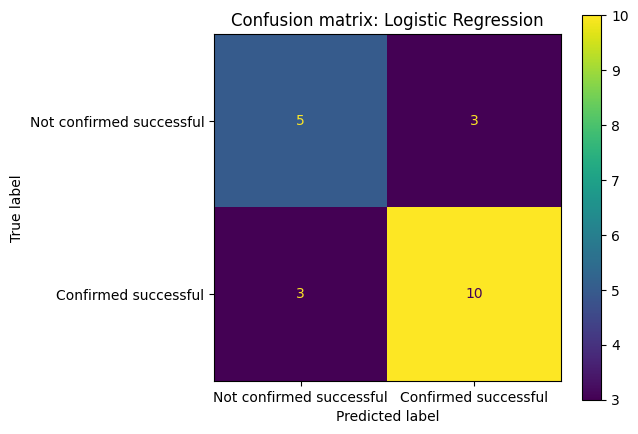

Saved: SpaceX_Confusion_Matrix.png


In [21]:
best_name = comparison.loc[0, "Model"]
best_pipeline = pipelines[best_name]
best_pipeline.fit(X_train, y_train)

y_pred = best_pipeline.predict(X_test)

print("Selected model:", best_name)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Test balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 3))
print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Not confirmed successful", "Confirmed successful"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
display(pd.DataFrame(
    cm,
    index=["Actual class 0", "Actual class 1"],
    columns=["Predicted class 0", "Predicted class 1"]
))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not confirmed successful", "Confirmed successful"]
)
disp.plot(values_format="d")
plt.title(f"Confusion matrix: {best_name}")
plt.tight_layout()
plt.savefig("SpaceX_Confusion_Matrix.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: SpaceX_Confusion_Matrix.png")


## 9. Conclusion template

After running the notebook, use the actual values printed above to complete this paragraph:

> Four classification models were compared using stratified five-fold cross-validation. The model with the highest mean cross-validation accuracy was **[model name]**, with an accuracy of **[value]**. Its held-out test accuracy was **[value]** and its balanced accuracy was **[value]**. These results should be interpreted cautiously because the dataset contains only 101 launches. In addition, class 0 means that a confirmed successful landing was not recorded; it does not necessarily mean that the booster crashed. More landing records and a clearer outcome definition would improve future analysis.

Do not fill in the bracketed values until the notebook has run.


## 10. Save your work

1. Save this notebook as `SpaceX_Landing_Classification.ipynb`.
2. Keep `Spacex.csv` in the same folder.
3. Run all cells from top to bottom.
4. Save the two chart images created by the notebook.
5. Record the actual model comparison and test results in your presentation.
6. Upload the completed notebook and chart images to your GitHub repository.

**Reminder:** These are exploratory educational models, not a dependable system for making real launch decisions.